In [2]:
from dfft.models.aribtrage import BatteryArbitrage
import numpy as np

Total Profit for the day: $853.26


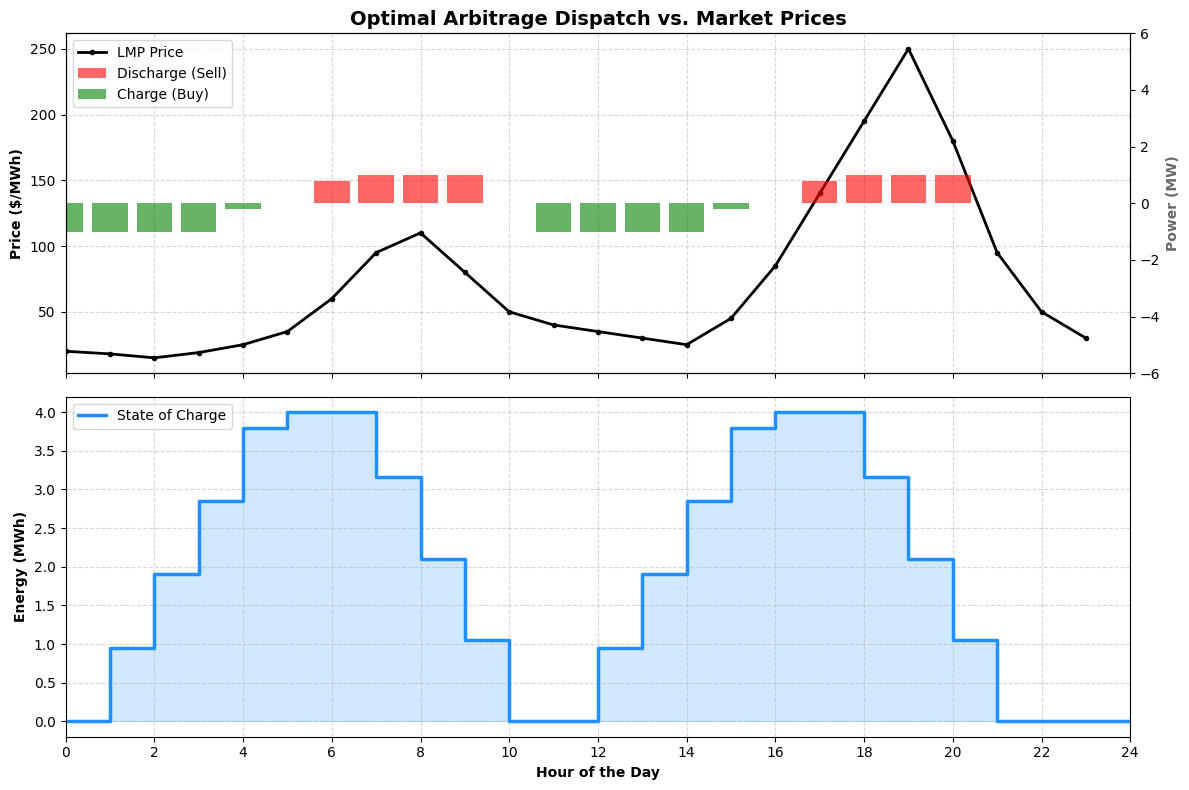

In [6]:
# A synthetic 24-hour price curve designed to force clear arbitrage behavior
dummy_prices = np.array([
    20.0, 18.0, 15.0, 19.0, 25.0, 35.0,  # Hours 0-5: Nighttime lows (Prime charging time)
    60.0, 95.0, 110.0, 80.0, 50.0, 40.0, # Hours 6-11: Morning peak (Will it discharge here?)
    35.0, 30.0, 25.0, 45.0, 85.0, 140.0, # Hours 12-17: Midday solar lull, building to evening
    195.0, 250.0, 180.0, 95.0, 50.0, 30.0 # Hours 18-23: Massive evening spike (Prime discharging time)
])

# 1. Instantiate the environment
# Using a standard 2-hour grid-scale battery: 50 MW power, 100 MWh capacity
bess_env = BatteryArbitrage()

# 2. Solve for this specific dummy day
results = bess_env.solve(dummy_prices)

# 3. Print the high-level financials
print(f"Total Profit for the day: ${results['profit']:,.2f}")

# 4. Generate the visualization
bess_env.plot_solution()